# ChurnGuard: exploratory analysis
Run from the `notebooks/` folder or the project root. The dataset must be at `data/Telco_customer_churn.xlsx`.

In [1]:
import sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt, pandas as pd, seaborn as sns
from src.data import load_raw, load_xy, EXCLUDED, FEATURES
sns.set_theme(style="whitegrid")
raw = load_raw()
print(raw.shape)
raw.dtypes.to_frame("dtype").join(raw.isna().sum().rename("missing")).T

(7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
dtype,str,int64,str,str,str,int64,str,float64,float64,str,...,str,str,str,float64,object,str,int64,int64,int64,str
missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5174


In [2]:
print("Duplicate rows:", raw.duplicated().sum(), "| duplicate CustomerIDs:", raw["CustomerID"].duplicated().sum())
print("Total Charges blank/invalid:", pd.to_numeric(raw["Total Charges"], errors="coerce").isna().sum())
print(raw.loc[pd.to_numeric(raw["Total Charges"], errors="coerce").isna(), "Tenure Months"].value_counts().to_dict(), "<- tenure of those rows")
X, y, _ = load_xy()
print("Model features:", len(FEATURES), "| excluded:", EXCLUDED)
X.describe().T

Duplicate rows: 0 | duplicate CustomerIDs: 0
Total Charges blank/invalid: 11
{0: 11} <- tenure of those rows


Model features: 19 | excluded: ['CustomerID', 'Churn Label', 'Churn Value', 'Churn Score', 'Churn Reason', 'CLTV', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude']


,count,mean,std,min,25%,50%,75%,max
Tenure Months,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
Monthly Charges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
Total Charges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


In [3]:
counts = y.value_counts().rename({0: "No churn", 1: "Churn"})
print(pd.DataFrame({"count": counts, "percent": (counts / len(y) * 100).round(2)}))
d = X.assign(churn=y)
d["Tenure Group"] = pd.cut(d["Tenure Months"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
def rate(col):
    return d.groupby(col, observed=True)["churn"].agg(churn_rate="mean", customers="size").round(3)
for col in ["Contract", "Tenure Group", "Internet Service", "Tech Support", "Payment Method"]:
    display(rate(col))

             count  percent
Churn Value                
No churn      5174    73.46
Churn         1869    26.54


,churn_rate,customers
Contract,,
Month-to-month,0.427,3875
One year,0.113,1473
Two year,0.028,1695


,churn_rate,customers
Tenure Group,,
0-12,0.474,2186
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


,churn_rate,customers
Internet Service,,
DSL,0.190,2421
Fiber optic,0.419,3096
No,0.074,1526


,churn_rate,customers
Tech Support,,
No,0.416,3473
No internet service,0.074,1526
Yes,0.152,2044


,churn_rate,customers
Payment Method,,
Bank transfer (automatic),0.167,1544
Credit card (automatic),0.152,1522
Electronic check,0.453,2365
Mailed check,0.191,1612


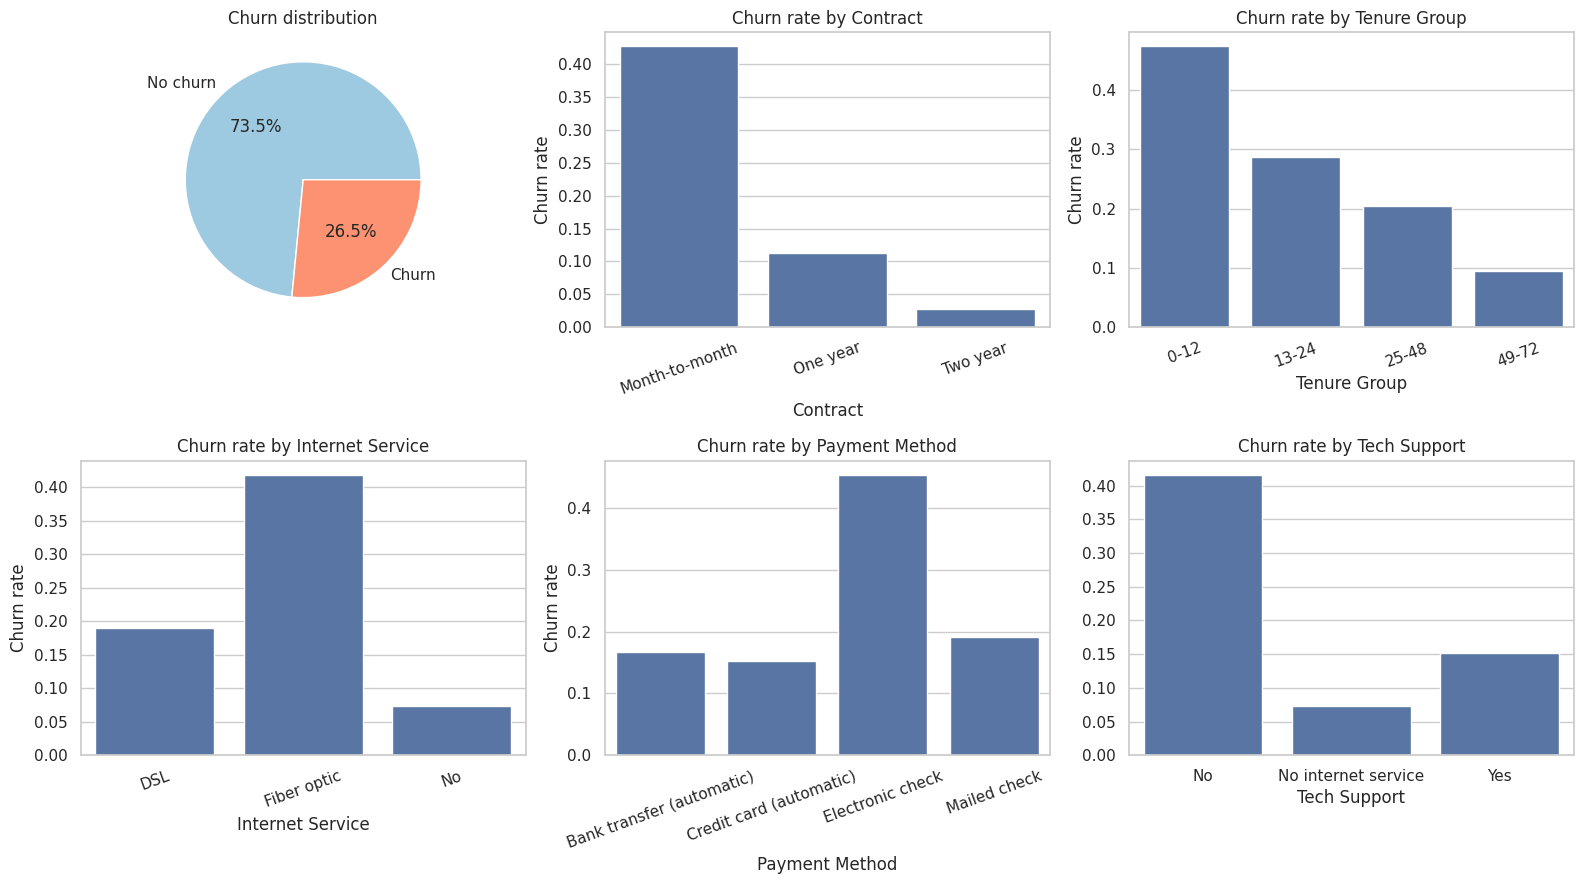

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes[0, 0].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=["#9ecae1", "#fc9272"]); axes[0, 0].set_title("Churn distribution")
for ax, col in zip(axes.flat[1:5], ["Contract", "Tenure Group", "Internet Service", "Payment Method"]):
    r = rate(col)["churn_rate"]
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color="#4c72b0")
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate"); ax.tick_params(axis="x", rotation=20)
r = rate("Tech Support")["churn_rate"]
sns.barplot(x=r.index, y=r.values, ax=axes[1, 2], color="#4c72b0"); axes[1, 2].set_title("Churn rate by Tech Support")
plt.tight_layout(); plt.show()

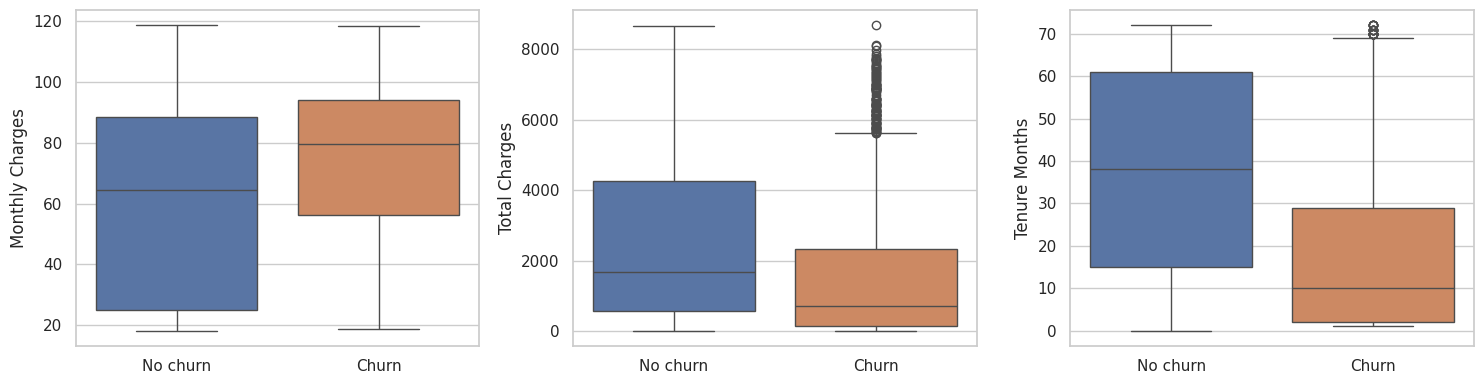

,Monthly Charges,Total Charges,Tenure Months
churn,,,
0,64.4,1683.6,38.0
1,79.6,703.6,10.0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Monthly Charges", "Total Charges", "Tenure Months"]):
    sns.boxplot(data=d, x="churn", y=col, ax=ax, hue="churn", legend=False); ax.set_xticks([0, 1], ["No churn", "Churn"]); ax.set_xlabel("")
plt.tight_layout(); plt.show()
d.groupby("churn")[["Monthly Charges", "Total Charges", "Tenure Months"]].median().round(1)

## Business observations (from the results above)
- **Class balance:** 26.5% of the 7,043 customers churned, so accuracy would be misleading and PR-AUC is the primary metric.
- **Contract:** month-to-month customers churn at 42.7%, versus 11.3% on one-year and 2.8% on two-year contracts.
- **Tenure:** churn is 47.4% in the first 12 months and falls to 9.5% after 48 months. The first year is the critical retention window.
- **Internet service:** fiber optic customers churn at 41.9% versus 19.0% for DSL.
- **Tech support:** customers with internet but no tech support churn at 41.6%, versus 15.2% with it (customers with no internet churn at 7.4%).
- **Payment method:** electronic check customers churn at 45.3%, roughly 2.5 to 3 times the rate of automatic payment methods (15.2% to 16.7%).
- **Charges:** churners have a higher median monthly charge ($79.65 vs $64.43) but a much lower median total charge ($703.55 vs $1,683.60), because they leave early.
- These are associations, not proof of cause. For example, electronic check may proxy for other customer traits.
- 11 blank `Total Charges` values all belong to customers with tenure 0; they are imputed in the pipeline rather than dropped.